<a href="https://colab.research.google.com/github/oliviaberset/2026_solute_transport/blob/main/E3_isotopes_CH_IRP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Water stable isotopes from rainfall to runoff

We will explore how the stable isotope composition of precipitation is transformed upon traveling through a watershed and results in a streamflow isotope composition that is much more damped and possibly delayed. We will link this transformation to water transit times.

## The data

The water isotopes dataset published by [Staudinger et al. (2020)](https://essd.copernicus.org/articles/12/3057/2020/) includes $^{18}\textrm{O}$ and $^{2}\textrm{H}$ values sampled in streamflow every 1-2 weeks at 23 Swiss sites over 8 years. Additionally, the dataset includes monthly estimates of the isotope composition of rainfall over the entire catchments. The data are available at [this Zenodo repository](https://doi.org/10.5281/zenodo.4057967).

The sites are visible in this map from Staudinger et al. (2020, Figure 1), which also shows the catchments' regime:

![](essd-12-3057-2020-f01-web.png)


And the timeseries of $\delta^{18}\textrm{O}$ from Staudinger et al., (2020, Figure 2) is reported below:

![](essd-12-3057-2020-f02-web.png)

Another useful study based on a similar dataset is [von Freyberg et al (2018)](https://doi.org/10.5194/hess-22-3841-2018)

## Introduction

To help you with the exercise development, a script `aux_functions.py` already includes useful functions to process the data. In particular, the function `CH_IRP_data_load` loads data from the different data files and generates three Pandas dataframes:

- `dfp`, with all the isotope data in **precipitation**
- `dfq`, with all the isotope data in **streamflow**
- `SiteInfo`, with useful info about the sites

#### Import the data

In [ ]:
# load the main packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

#import warnings
#warnings.filterwarnings('ignore')

In [ ]:
# Import the data
from aux_functions import CH_IRP_data_load

# Define the path (you may have a different one)
path_isoprecip = os.path.join("CH-IRP","isotopes_precipitation")
path_isostreamflow = os.path.join("CH-IRP","isotopes_streamflow")

# Load all the data into a pd.DataFrame
dfp, dfq, SiteInfo = CH_IRP_data_load(path_isoprecip, path_isostreamflow)

# Add a month, year and day of the year variable
dfp["month"] = dfp["date"].dt.month
dfq["month"] = dfq["Sampling_date"].dt.month

# Define month abbreviations (useful for plotting)
months = ["J","F","M","A","M","J","J","A","S","O","N","D"]
months_3digit = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

# Also join some info from the SiteInfo dataframe to the isotope dataframes
dfp = pd.merge(dfp, SiteInfo[["catchmentID","regime","catchmentElevation"]], how='left')
dfq = pd.merge(dfq, SiteInfo[["catchmentID","regime","catchmentElevation"]], how='left')

In [ ]:
# Overview of the isotopes measured in streamflow
display(dfq.head(3))

,Sampling_date,Analysis_date,d18O_mean,d2H_mean,D_excess,SamplQ_idx,Q_percentile,Double_measurement,Outlier_2H,Outlier_18O,Comment,catchmentID,month,regime,catchmentElevation
0,2010-07-20,2011-02-03,-8.62,-61.5,7.51,0.53,0.7997,T,1.740,1.690,NaN,AAC,7,pluvial,476.0
1,2010-08-05,2011-02-03,-10.74,-78.7,7.18,7.72,0.0149,T,-1.549,-1.280,NaN,AAC,8,pluvial,476.0
2,2010-08-24,2011-02-03,-8.51,-61.0,7.15,0.60,0.4619,T,1.841,1.846,NaN,AAC,8,pluvial,476.0


In [ ]:
# Overview of the isotopes estimated in precipitation
display(dfp.head(3))

,date,d18O_prcp,d18O_source,dDeuterium_prcp,dDeuterium_source,catchmentID,month,regime,catchmentElevation
0,1990-01-01,-8.03,GNIP:1092900,-64.23,GNIP:1092900,AAC,1,pluvial,476.0
1,1990-02-01,-7.51,GNIP:1092900,-55.63,GNIP:1092900,AAC,2,pluvial,476.0
2,1990-03-01,-5.96,GNIP:1092900,-45.53,GNIP:1092900,AAC,3,pluvial,476.0


#### Initial data visualisation

Let's have a look at some characteristics of the data we imported!

***Differences among regimes***

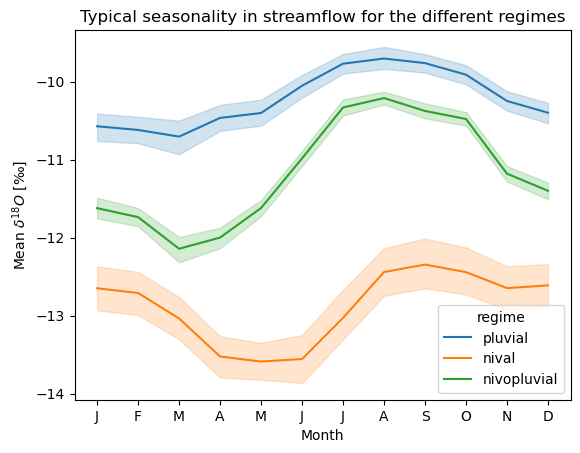

In [ ]:
# Focus on the general differences among regimes
g2 = sns.lineplot(
    data = dfq,
    x = "month",
    y = "d18O_mean",
    hue = "regime"
    )

plt.xticks(ticks=np.arange(1,13),labels=months)
plt.xlabel("Month")
plt.ylabel(r"Mean $\delta^{18}O$ [‰]")
plt.title('Typical seasonality in streamflow for the different regimes')
plt.show()

***Relationship between elevation and isotope composition***

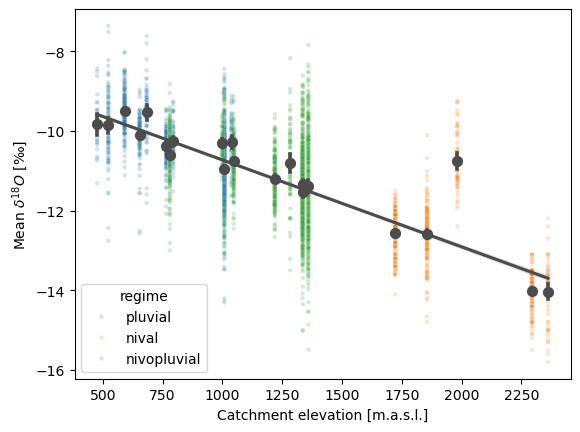

In [ ]:
# show the effect of elevation
g2 = sns.scatterplot(
    data = dfq,
    x = "catchmentElevation",
    y = "d18O_mean",
    hue = "regime",
    s = 10,
    alpha = .2
    )
g2 = sns.regplot(
    data = dfq,
    x = "catchmentElevation",
    y = "d18O_mean",
    #marker = 'none',
    x_estimator=np.mean,
    color=".3",
    )

plt.xlabel("Catchment elevation [m.a.s.l.]")
plt.ylabel(r"Mean $\delta^{18}O$ [‰]")
plt.show()


This relationship between elevation and isotope composition shold be familiar to you based on what you've seen during the course "Tracing biogeochemical processes and fluxes using isotope analysis".

All the sites follow a clear linear trend except for one: the RIA (Riale di Calneggia, Cavergno, Pontit), which is located in the Ticino canton. Would you be able to tell why this site has a different behavior compared to all other sites?

---

## Exercise

The goal is to quantify transit times in watersheds based on $\delta^{18}\textrm{O}$ data and a stationary transit time distribution model (see lecture 3 materials). You can do the exercise for any of the watersheds, but the **Biber, Biberbrugg (BIB)** and **Ergolz, Liestal (ERG)** catchments are most suitable because of their pluvial regime and completeness of the data series.

As a transit time distribution model, you will be using a [**gamma distribution**](https://en.wikipedia.org/wiki/Gamma_distribution). You need to search for the *shape* and *scale* parameters that give you a satisfactory visual fit of the measurements.

### Questions/Tasks

1. What happens to the simulation of streamflow $\delta^{18}O$ when you change the shape parameter? And when you change the scale parameter?

2. Try various parameter combinations (with **shape** parameter in the interval **0.3–1** and **scale** parameter in the interval **500–3000**) until you find a TTD that gives a good visual fit to the measured $\delta^{18}O$ in streamflow. Look at the TTD: what landscape properties can explain this distribution of transit times?

3. Compute the young water fraction ($F_{yw}$) with the standard deviation method (see lecture material). How does it compare with the $F_{yw}$ determined from the gamma distribution?

### Useful operations

#### Vizualise the observed precipitation and streamflow $\delta^{18}O$ data

You will try to reproduce the observed streamflow concentrations

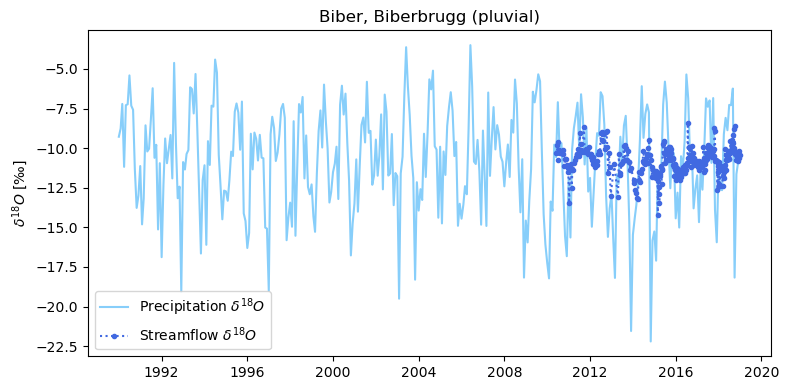

In [ ]:
# Select one site
site_sel = 'BIB'  # Choose between 'BIB' or 'ERG'

# Extract data (in precip and streamflow) from the selected site
dfp_sel = dfp[dfp["catchmentID"] == site_sel].sort_values("date")
dfq_sel = dfq[dfq["catchmentID"] == site_sel].dropna(subset=["d18O_mean"]).sort_values("Sampling_date")
site_fullname = SiteInfo.loc[SiteInfo["catchmentID"]==site_sel,"catchmentName"].to_string(index=False)
site_regime = SiteInfo.loc[SiteInfo["catchmentID"]==site_sel,"regime"].to_string(index=False)

# Display the data
fig, ax = plt.subplots(figsize=(8,4))

ax.plot(dfp_sel["date"], dfp_sel["d18O_prcp"], label=r'Precipitation $\delta^{18}O$',
        color='lightskyblue')
ax.plot(dfq_sel["Sampling_date"], dfq_sel["d18O_mean"],".:", label=r'Streamflow $\delta^{18}O$',
        color='royalblue')

ax.legend()
ax.set_title(f'{site_fullname} ({site_regime})')
ax.set_ylabel(r'$\delta^{18}O$ [‰]')

fig.tight_layout()

#### Gamma distributions as transit time distribution models

To create the gamma distribution you can first create a vector of transit times values (using `x_values = np.arange(1, nmax)`, where `nmax` is the maximum transit time that you take into account, for example 20 $\cdot$ 365 days). Then, you can compute the gamma distribution over this transit time vector, with the `gamma` object from the `scipy.stats` package. See example below.

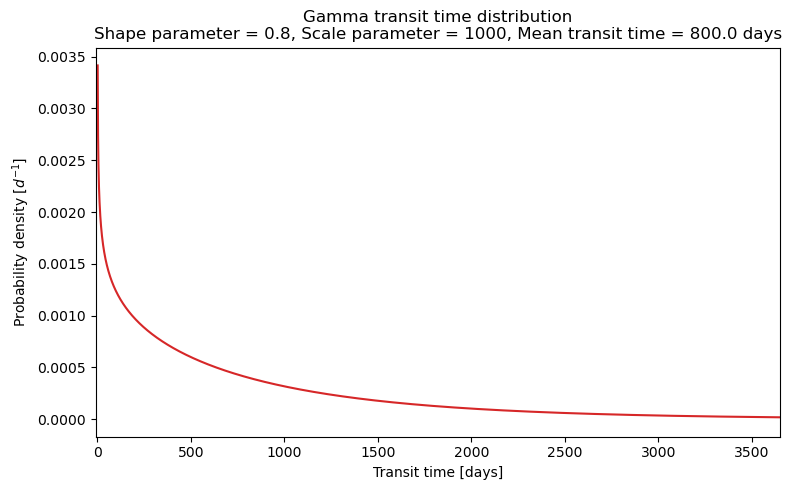

In [ ]:
from scipy.stats import gamma

# Define the model parameters
shape = 0.8  # shape parameter
scale = 1000  # scale parameter

# Evaluate the gamma distribution
nmax = round(365*20)  # length of the pdf, it is useful to take it as long as the data allows it to avoid truncation
x_values = np.arange(1, nmax)  # transit times in days (start from 1 to avoid Inf values)
gamma_pdf = gamma.pdf(x_values, shape, scale=scale)
mean = scale * shape  # mean transit time (mean = shape * scale)

# Show the distribution in a figure
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_values, gamma_pdf, color='tab:red')
ax.set_xlabel('Transit time [days]')
ax.set_ylabel(r'Probability density [$d^{-1}$]')
ax.set_xlim([-10, 3650])
ax.set_title('Gamma transit time distribution\n'
             + f'Shape parameter = {shape}, Scale parameter = {scale}, Mean transit time = {mean} days')
fig.tight_layout()

#### Setting up the convolution

- For numerical accuracy, it is important to re-interpolate the input isotope data at daily frequency. To do so, there are useful methods in Pandas, such as `resample()` and `interpolate()`. You can combine them as in:

```python
    var_sel = ["date","d18O_prcp","dDeuterium_prcp"]  # choose which variables will be interpolated
    dfp_day = (
        dfp.loc[:,var_sel]
        .set_index('date')  # set the date as index (necessary to use the methods)
        .resample("D")  # upsample to daily values
        .interpolate(method='linear')  # interpolate linearly
        )
```

- To make computations (like the convolution), it is necessary to convert the pandas Series into a numpy array. You can do this with the method `to_numpy()`, for example:
```python
    my_numpy_array = df_my_pandas_dataframe["d18O_prcp"].to_numpy()  # choose which variable will be converted
```

- To do the convolution, you can use the `convolve` function from the `scipy.signal` package. Remember that the convolution operation generally gives you an output that is longer than your input. However, we are not interested in those extra data points and so it is good to trim the output signal to the lenght of the input signal. See the code example given in class.

## Solution